# 01 Data audit: G.25 occupancy sensor

This notebook shows what the raw sensor data looks like, what the cleaning does, and how the room is used. All the logic lives in the `occupancy` package (tested with pytest); this notebook only calls those functions and makes figures.

Run `python main.py` from the repository root first, so the cleaned data and audit table exist.

Figures are saved to `reports/figures/` for the report.

In [1]:
import os
from pathlib import Path

# Work from the repository root so paths match main.py
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import matplotlib.pyplot as plt
import pandas as pd

from occupancy.data import FLOORSPACES, load_occupancy_events, remove_duplicates, to_regular_grid

FIGURES = Path("reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

# Colours (validated colour-blind-safe set) and plain styling
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 11,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.6, "legend.frameon": False,
})

## 1. Data audit

Counts produced by `audit_events` (saved by `main.py`). Nothing is changed at this step; these numbers justify each cleaning decision.

In [2]:
audit = pd.read_csv("reports/audit_G25.csv", index_col=0)
audit

,value
rows,1500394
first_timestamp,2024-03-03 15:06:30+11:00
last_timestamp,2026-04-22 22:09:42+10:00
duplicate_timestamps,3
unknown_status,0
negative_headcount,0
status_headcount_mismatch,0
max_headcount,38
gaps_over_limit,1755
gaps_over_limit_after_empty,1702


## 2. Raw events vs 15-minute blocks (one example week)

The sensor sends a reading whenever it has something to report (every few seconds while people are present), so the raw data is irregular. `to_regular_grid` holds each reading until the next one and takes the time-weighted average over each 15-minute block.

In [3]:
events = load_occupancy_events("data/raw/5occupancySensor_MayToDec2024_9MRows.csv", FLOORSPACES["G25"])
events, _ = remove_duplicates(events)
series = pd.read_parquet("data/processed/G25_15min.parquet")["headcount"]
print(f"{len(events):,} raw events -> {len(series):,} blocks of 15 minutes")

1,500,391 raw events -> 74,788 blocks of 15 minutes


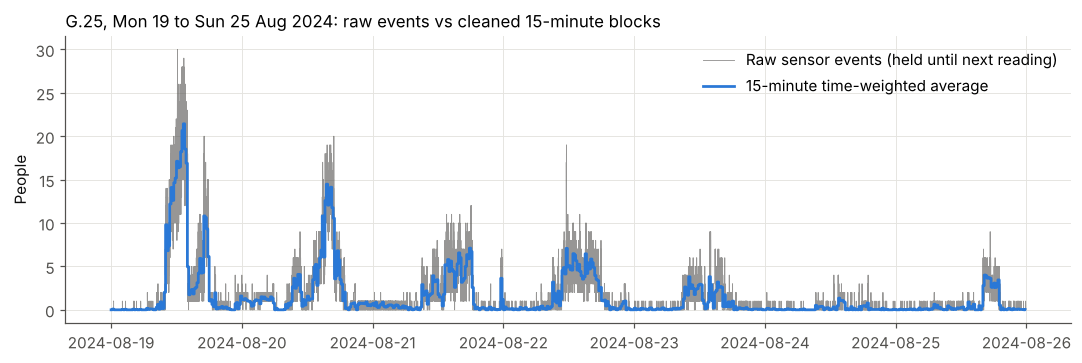

In [4]:
start, end = "2024-08-19", "2024-08-26"   # a teaching week in semester 2, 2024
tz = series.index.tz
week_events = events[(events["timestamp"] >= pd.Timestamp(start, tz=tz)) &
                     (events["timestamp"] < pd.Timestamp(end, tz=tz))]
week_blocks = series[start:"2024-08-25"]

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.step(week_events["timestamp"], week_events["headcount"], where="post",
        color=MUTED, linewidth=0.6, alpha=0.6, label="Raw sensor events (held until next reading)")
ax.step(week_blocks.index, week_blocks.to_numpy(), where="post",
        color=BLUE, linewidth=1.8, label="15-minute time-weighted average")
ax.set_ylabel("People")
ax.set_title("G.25, Mon 19 to Sun 25 Aug 2024: raw events vs cleaned 15-minute blocks", loc="left")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIGURES / "fig1_example_week.png")
plt.show()

## 3. Average day: weekdays vs weekends

Average headcount for each hour of the day over the whole period (4 Mar 2024 to 21 Apr 2026).

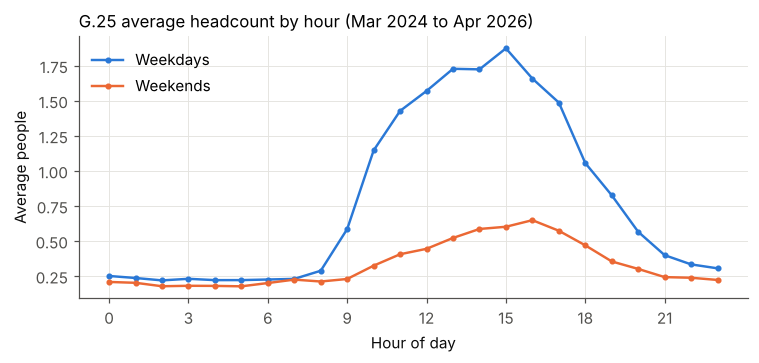

block_start,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Weekdays,0.25,0.24,0.22,0.23,0.22,0.22,0.23,0.23,0.29,0.59,...,1.72,1.87,1.66,1.49,1.06,0.83,0.57,0.40,0.33,0.31
Weekends,0.21,0.20,0.18,0.18,0.18,0.18,0.20,0.22,0.21,0.23,...,0.59,0.60,0.65,0.57,0.47,0.35,0.30,0.24,0.24,0.22


In [5]:
hourly = series.groupby([series.index.dayofweek >= 5, series.index.hour]).mean().unstack(0)
hourly.columns = ["Weekdays", "Weekends"]

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(hourly.index, hourly["Weekdays"], color=BLUE, marker="o", markersize=3, label="Weekdays")
ax.plot(hourly.index, hourly["Weekends"], color=ORANGE, marker="o", markersize=3, label="Weekends")
ax.legend(loc="upper left")
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Average people")
ax.set_title("G.25 average headcount by hour (Mar 2024 to Apr 2026)", loc="left")
fig.tight_layout()
fig.savefig(FIGURES / "fig2_weekday_weekend_profile.png")
plt.show()
hourly.round(2).T

## 4. Use dropped after 2024

Weekly average of weekday headcount between 9am and 5pm. The dashed line marks the train/test split used by the models (3 Mar 2025). This drop is why models are tested walk-forward and why monthly retraining was added.

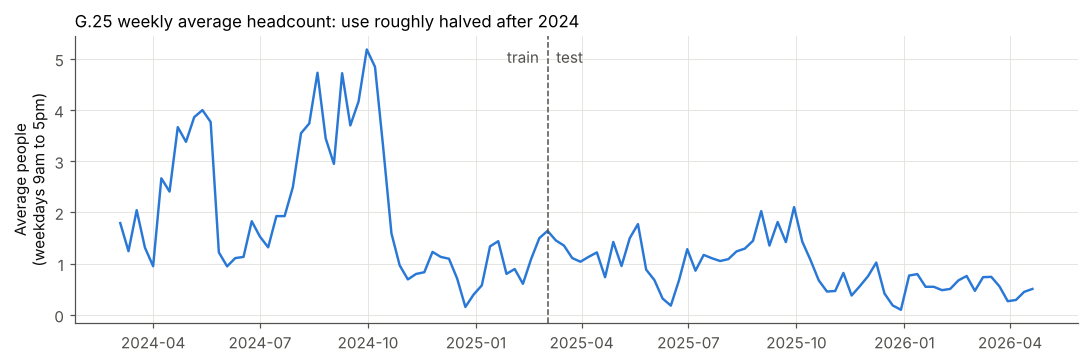

,"average people, weekdays 9am-5pm"
2024 S1 teaching,2.66
2024 S2 teaching,3.75
2025 S1 teaching,1.25
2025 S2 teaching,1.38
2026 S1 teaching (to 17 Apr),0.50


In [6]:
day = series[(series.index.dayofweek < 5) & (series.index.hour >= 9) & (series.index.hour < 17)]
weekly = day.groupby(day.index.tz_localize(None).to_period("W-SUN")).mean()
weekly.index = weekly.index.start_time

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(weekly.index, weekly.to_numpy(), color=BLUE)
split = pd.Timestamp("2025-03-03")
ax.axvline(split, color=MUTED, linestyle="--", linewidth=1)
ax.text(split, weekly.max() * 0.95, "train  ", ha="right", color=MUTED)
ax.text(split, weekly.max() * 0.95, "  test", ha="left", color=MUTED)
ax.set_ylabel("Average people\n(weekdays 9am to 5pm)")
ax.set_title("G.25 weekly average headcount: use roughly halved after 2024", loc="left")
fig.tight_layout()
fig.savefig(FIGURES / "fig3_weekly_drift.png")
plt.show()

periods = {
    "2024 S1 teaching": ("2024-03-11", "2024-05-24"),
    "2024 S2 teaching": ("2024-07-22", "2024-10-18"),
    "2025 S1 teaching": ("2025-03-03", "2025-05-30"),
    "2025 S2 teaching": ("2025-07-28", "2025-10-24"),
    "2026 S1 teaching (to 17 Apr)": ("2026-03-02", "2026-04-17"),
}
pd.Series({k: day[a:b].mean() for k, (a, b) in periods.items()},
          name="average people, weekdays 9am-5pm").round(2).to_frame()

## 5. Check: the fast resampler against a slow loop version

`to_regular_grid` (vectorised pandas) and `to_regular_grid_loop` (plain Python loop, in `occupancy.performance`) are written completely differently. If they agree on the real data, that is good evidence the conversion is right. Timing is in `benchmark.py`.

In [7]:
from occupancy.performance import to_regular_grid_loop

sample = events[(events["timestamp"] >= pd.Timestamp("2024-08-01", tz=tz)) &
                (events["timestamp"] < pd.Timestamp("2024-09-01", tz=tz))]
fast = to_regular_grid(sample)
slow = to_regular_grid_loop(sample)
print(f"{len(sample):,} events, {len(fast):,} blocks")
print(f"Same blocks: {fast.index.equals(slow.index)}")
print(f"Largest difference: {(fast - slow).abs().max():.2e} people")

91,693 events, 2,973 blocks
Same blocks: True
Largest difference: 0.00e+00 people


## 6. Independent check: CO2 in a nearby room

People breathe out CO2, so if the occupancy data reflects real use of the building, CO2 should rise and fall at the same times. The only CO2 sensor with useful data is in room G.38 (building 60), not G.25, and it only covers Feb to Jun 2024. So this checks the building's daily rhythm, not G.25's exact counts. Correlations are saved by `main.py` in `reports/co2_crosscheck.csv`.

overlap_start                  2024-03-04 00:00:00+11:00
overlap_end                    2024-06-14 03:00:00+10:00
overlap_hours                                       2453
overlap_days                                         103
corr_weekday_hourly_profile                     0.904706
corr_daily_mean                                 0.580945
corr_hourly_lag0h                                0.47152
corr_hourly_lag1h                               0.487874
corr_hourly_lag2h                               0.472435


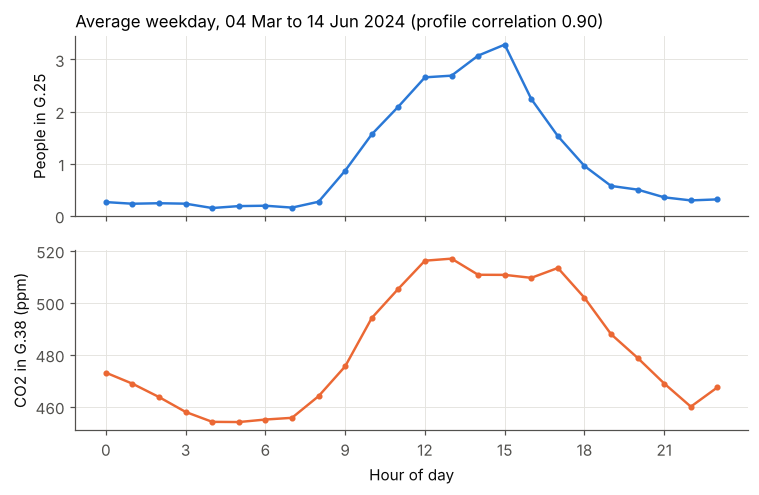

In [8]:
from occupancy.data import CO2_SENSOR_G38, load_env_sensor
from occupancy.evaluate import co2_crosscheck

co2 = load_env_sensor("data/raw/5EnvSensor_MayToDec2024_180kRows.csv", CO2_SENSOR_G38)
check = co2_crosscheck(series, co2)
print(check.to_string())

hourly = pd.concat({"headcount": series.resample("1h").mean(),
                    "co2": co2.resample("1h").mean()}, axis=1, sort=True).dropna()
weekday = hourly[hourly.index.dayofweek < 5]
profile = weekday.groupby(weekday.index.hour).mean()

# Two panels sharing the hour axis (different units, so no shared y-axis)
fig, (top, bottom) = plt.subplots(2, 1, figsize=(7, 4.6), sharex=True)
top.plot(profile.index, profile["headcount"], color=BLUE, marker="o", markersize=3)
top.set_ylabel("People in G.25")
top.set_title(f"Average weekday, {check['overlap_start']:%d %b} to {check['overlap_end']:%d %b %Y} "
              f"(profile correlation {check['corr_weekday_hourly_profile']:.2f})", loc="left")
bottom.plot(profile.index, profile["co2"], color=ORANGE, marker="o", markersize=3)
bottom.set_ylabel("CO2 in G.38 (ppm)")
bottom.set_xlabel("Hour of day")
bottom.set_xticks(range(0, 24, 3))
fig.tight_layout()
fig.savefig(FIGURES / "fig4_co2_crosscheck.png")
plt.show()